# Topic Identification and Classification of Short Texts
### IT5072 – Natural Language Processing · Coursework 02 · Student ID: MS26900636

**Goal.** Build a model that reads any **three-sentence text** and assigns it to one of **five classes**:
**Medical**, **Sports**, **Religion**, **Politics**, or **Other** (a text that belongs to none of the four given domains).

**Approach in one line.** Unsupervised topic modeling (LDA and NMF) is used to *discover and explain* the latent themes of the
corpora, and a supervised TF-IDF classifier with a calibrated confidence threshold is used to *decide* the final class,
including the open-set *Other* class.

| Section | Content | Marking criterion |
|---|---|---|
| 1 | Theoretical approach | Theory (30%) |
| 2 – 4 | Setup, data exploration, preprocessing | Implementation (30%) |
| 5 | Evaluation design (splits and 3-sentence chunks) | Implementation |
| 6 | Topic modeling: LDA and NMF | Implementation |
| 7 | Supervised classifiers | Implementation |
| 8 | The *Other* class: confidence threshold | Implementation / Testing |
| 9 | Final evaluation on held-out and unseen-topic data | Testing (30%) |
| 10 | Testing with hand-written outside texts | Testing (30%) |
| 11 | Discussion and conclusion | – |

**Data layout** (all paths are relative to this notebook):
```
data/
├── train/                       # given corpora, one folder per domain
│   ├── medical/sci.med/
│   ├── sports/rec.sport.baseball/, rec.sport.hockey/
│   ├── religion/soc.religion.christian/, talk.religion.misc/
│   └── politics/talk.politics.guns/, talk.politics.mideast/, talk.politics.misc/
└── outside/                     # data NOT taken from the given corpora
    ├── other_20ng/tune/         # unrelated newsgroups used to tune the Other threshold
    ├── other_20ng/test/         # different unrelated newsgroups, used only for testing
    └── handmade/<class>/        # 30 newly written 3-sentence texts (6 per class)
```

## 1. Theoretical Approach

### 1.1 Problem definition
Topic identification is the task of finding the theme of a text. Topic *modeling* answers the question
"what themes exist in this collection?" without labels, while topic *classification* answers
"which known theme does this new text belong to?". This coursework requires both:

* The corpora are already grouped by domain, so the four domains are **known classes** (a supervised, closed-set problem).
* A fifth class, **Other**, has **no training data** at all. Any text from an unseen subject (cooking, finance, technology …)
  must be recognised as "none of the above". This is an **open-set recognition** problem: the model must know when it does not know.
* Inputs are only **three sentences** long (roughly 30–70 words). Short texts are sparse: each contains few of the
  vocabulary words, so the model must rely on a small number of strong, topic-bearing keywords.

The proposed solution is a **hybrid** pipeline:

```
 raw posts ──► cleaning ──► tokens ──┬──► Bag-of-Words ──► LDA ─────────┐  (unsupervised: discover & explain topics)
                                     │                                   ├──► topic → domain mapping, topic-based classifier
                                     ├──► TF-IDF ────────► NMF ─────────┘
                                     │
                                     └──► TF-IDF (1–2-grams) ──► NB / LogReg / SVM ──► class probabilities
                                                                                              │
                                                       max probability < τ ?  ──yes──► "Other"
                                                                              └─no───► Medical / Sports / Religion / Politics
```

### 1.2 Corpus
The given corpora are eight newsgroups from the *20 Newsgroups* collection (Lang, 1995), mapped to four domains:

| Domain | Newsgroups | Posts |
|---|---|---|
| Medical | sci.med | 990 |
| Sports | rec.sport.baseball, rec.sport.hockey | 1,993 |
| Religion | soc.religion.christian, talk.religion.misc | 1,625 |
| Politics | talk.politics.guns, talk.politics.mideast, talk.politics.misc | 2,625 |

The classes are **imbalanced** (Politics has about 2.7× as many posts as Medical), which influences the choice of
evaluation metric (macro-F1) and the use of class weighting.

### 1.3 Preprocessing
Raw Usenet posts contain much text that is either noise or *leakage* (information that reveals the label but would never
appear in a real input):

| Step | Reason |
|---|---|
| Remove headers (`From`, `Organization`, `Lines`, …), keep only `Subject` | Headers name the newsgroup or the author's institution, which would let the model "cheat". The subject line is genuine topical content. |
| Remove quoted replies (`>` lines) and "*X writes:*" lines | Quoted text belongs to another post and duplicates content. |
| Remove signatures (after `--`), e-mail addresses, URLs, ASCII art | Not topical; signatures repeat across posts of the same author and cause over-fitting. |
| Lower-casing, keep alphabetic tokens of length ≥ 3 | Normalises surface forms and removes numbers and punctuation. |
| Stop-word removal (NLTK list + Usenet words like *writes*, *article*) | Function words carry no topic information. |
| Lemmatisation (WordNet) | Groups inflected forms (*doctors → doctor*, *games → game*) and reduces sparsity. Lemmatisation is chosen over stemming because it keeps real words, which makes topics easier to read. |

### 1.4 Text representation (vector space model)
Each document is represented as a vector over the vocabulary $V$.

* **Bag-of-Words (BoW)**: the count $tf(t,d)$ of each term $t$ in document $d$. Word order is ignored. LDA is defined over counts,
  so it uses BoW.
* **TF-IDF** (Salton & Buckley, 1988) re-weights counts so that words frequent in a document but rare in the collection get high weight:

$$\text{tfidf}(t,d) = \big(1 + \log tf(t,d)\big)\cdot \log\frac{1+N}{1+df(t)} + 1$$

  where $N$ is the number of documents and $df(t)$ the number of documents containing $t$. The *sublinear* $1+\log tf$ term stops
  long posts from dominating. Vectors are L2-normalised so that short (3-sentence) and long texts are comparable.
* **n-grams**: unigrams and bigrams are used for classification so that phrases such as *gun control*, *blood pressure* or *world series*
  become features.

### 1.5 Unsupervised topic modeling

**Latent Dirichlet Allocation (LDA)** (Blei, Ng & Jordan, 2003) is a generative probabilistic model. It assumes that each document
is a *mixture of topics* and each topic is a *mixture of words*:

1. For each topic $k = 1..K$: draw a word distribution $\beta_k \sim \text{Dirichlet}(\eta)$.
2. For each document $d$: draw topic proportions $\theta_d \sim \text{Dirichlet}(\alpha)$.
3. For each word position $n$ in $d$: draw a topic $z_{dn} \sim \text{Multinomial}(\theta_d)$, then the word $w_{dn} \sim \text{Multinomial}(\beta_{z_{dn}})$.

Only the words $w$ are observed. Learning reverses this process, estimating the hidden $\theta$ and $\beta$ from the observed words by
maximising $p(w \mid \alpha,\eta)$. The exact posterior is intractable, so gensim uses **online variational Bayes** (Hoffman et al., 2010).
Small Dirichlet parameters encode the belief that a document uses only a few topics and a topic uses only a few words. Here $\alpha$ and $\eta$
are learned from the data (`'auto'`).

**Choosing the number of topics $K$.** $K$ is a hyper-parameter. It is selected with **topic coherence $C_v$** (Röder et al., 2015). $C_v$
measures how often the top words of a topic co-occur in the corpus (using sliding windows, NPMI and cosine similarity). A higher value
means more human-interpretable topics.

**Non-negative Matrix Factorisation (NMF)** (Lee & Seung, 1999) is a linear-algebra alternative. The TF-IDF matrix
$V \in \mathbb{R}^{n\times m}_{\ge 0}$ is approximated by two smaller non-negative matrices:

$$V \approx W H, \qquad \min_{W,H \ge 0} \lVert V - WH\rVert_F^2$$

$W$ (documents × topics) gives each document's topic weights, and $H$ (topics × words) gives each topic's word weights. The non-negativity
makes the factorisation *additive* (parts-based), so the topics are interpretable. NMF is deterministic given its initialisation and often
gives sharper topics on short texts, while LDA gives a full probabilistic model.

**From topics to domains.** Topic models produce *unlabelled* topics. Each topic is mapped to the domain in which it has the highest
average share, $\text{domain}(k) = \arg\max_c \frac{1}{|D_c|}\sum_{d\in D_c}\theta_{dk}$. A new text is then classified by summing
its topic proportions per domain. This gives a fully **topic-based classifier** that can be compared with the supervised one.

### 1.6 Supervised classification
Because labelled data exists, supervised learners can use it directly. Three linear classifiers on TF-IDF features are compared:

* **Multinomial Naive Bayes**: applies Bayes' rule with the "naive" assumption that words are conditionally independent given the class:
  $\hat{c} = \arg\max_c \; \log P(c) + \sum_{t} x_t \log P(t \mid c)$, where $P(t \mid c)$ uses Laplace/Lidstone smoothing. It is fast and a strong baseline for text.
  The class prior $P(c)$ is set to **uniform**. With the empirical prior, the largest class (Politics) would win every uncertain
  text, including off-topic ones that should be rejected as *Other*.
* **Logistic Regression (multinomial / softmax)**: a discriminative model,
  $P(c \mid x) = \dfrac{\exp(w_c^\top x + b_c)}{\sum_j \exp(w_j^\top x + b_j)}$, trained by minimising regularised cross-entropy.
  It outputs well-calibrated probabilities, which matter for the *Other* decision.
* **Linear Support Vector Machine**: finds the maximum-margin hyperplane (hinge loss + L2 penalty). It is often the most accurate model
  on high-dimensional sparse text. SVMs give scores rather than probabilities, so **Platt scaling** (sigmoid calibration, Platt, 1999) is applied with
  `CalibratedClassifierCV`.

`class_weight='balanced'` is used where supported to counter the class imbalance.

A fourth, **hybrid** model, *LDA topic proportions → Logistic Regression*, tests whether the compact topic representation
($K$ features instead of ~100k) is enough for classification.

### 1.7 Detecting the *Other* class (open-set recognition)
No training examples exist for *Other*, and "everything else" cannot be sampled completely. The model therefore uses a **reject option**
based on its confidence (the maximum-softmax-probability baseline of Hendrycks & Gimpel, 2017):

$$\hat{y}(x) = \begin{cases} \arg\max_c P(c\mid x) & \text{if } \max_c P(c\mid x) \ge \tau \\ \text{Other} & \text{otherwise}\end{cases}$$

A text about cooking contains few Medical/Sports/Religion/Politics keywords, so the probability mass is spread out and the maximum is low.
The threshold $\tau$ is **tuned** on a validation set that contains in-domain texts and *Other* texts from three unrelated newsgroups
(computer graphics, X-Windows, cars). It is then **tested** on four *different* unrelated newsgroups (space, for-sale, motorcycles,
electronics) and on hand-written texts. This shows the rule generalises to subjects it never saw, instead of memorising one kind of "other".

### 1.8 Evaluation protocol
* The given posts are split **at document level** into train (70%), validation (15%) and test (15%), stratified by domain.
  Splitting before chunking guarantees that no sentence from a test post was seen in training.
* Models are **trained on whole posts** (more context gives better word statistics) but **evaluated on three-sentence chunks** cut
  from the body of validation/test posts. This matches the real task. The subject line is excluded from chunks because real inputs have none.
* The validation set is used for every choice (model selection, $\tau$). The test set is used **once**, for the final numbers.
* Metrics: accuracy, per-class precision/recall/F1, **macro-F1** (the unweighted mean of class F1s, so the small Medical and *Other*
  classes count as much as Politics), and confusion matrices.

### References
* Blei, D. M., Ng, A. Y., & Jordan, M. I. (2003). Latent Dirichlet Allocation. *Journal of Machine Learning Research*, 3, 993–1022.
* Hendrycks, D., & Gimpel, K. (2017). A Baseline for Detecting Misclassified and Out-of-Distribution Examples in Neural Networks. *ICLR*.
* Hoffman, M., Bach, F., & Blei, D. (2010). Online Learning for Latent Dirichlet Allocation. *NeurIPS*.
* Lang, K. (1995). NewsWeeder: Learning to Filter Netnews. *ICML*.
* Lee, D. D., & Seung, H. S. (1999). Learning the parts of objects by non-negative matrix factorization. *Nature*, 401, 788–791.
* Manning, C. D., Raghavan, P., & Schütze, H. (2008). *Introduction to Information Retrieval*. Cambridge University Press.
* Platt, J. (1999). Probabilistic outputs for support vector machines. *Advances in Large Margin Classifiers*.
* Röder, M., Both, A., & Hinneburg, A. (2015). Exploring the Space of Topic Coherence Measures. *WSDM*.
* Salton, G., & Buckley, C. (1988). Term-weighting approaches in automatic text retrieval. *Information Processing & Management*, 24(5).
* Sievert, C., & Shirley, K. (2014). LDAvis: A method for visualizing and interpreting topics. *ACL Workshop on Interactive Language Learning*.

## 2. Setup
Libraries, random seeds (for reproducible results) and NLTK resources. Exact package versions are listed in `requirements.txt`.

In [1]:
import re, random, warnings, time
from pathlib import Path
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import sent_tokenize

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.decomposition import NMF
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

from gensim.corpora import Dictionary
from gensim.models import LdaModel, CoherenceModel
from wordcloud import WordCloud

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

for pkg in ['stopwords', 'wordnet', 'omw-1.4', 'punkt', 'punkt_tab']:
    nltk.download(pkg, quiet=True)

DATA = Path('data')
DOMAINS = ['medical', 'sports', 'religion', 'politics']
CLASSES = DOMAINS + ['other']
PALETTE = dict(zip(CLASSES, sns.color_palette('Set2', 5)))

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_colwidth', 110)
print('Setup complete.')

Setup complete.


## 3. Data Loading and Exploration
Every file is read from `data/train/<domain>/<newsgroup>/`. The folder name gives the label.

In [2]:
def read_file(path):
    return Path(path).read_text(encoding='latin-1')

rows = []
for domain in DOMAINS:
    for group_dir in sorted((DATA / 'train' / domain).iterdir()):
        for f in sorted(group_dir.iterdir()):
            rows.append({'domain': domain, 'newsgroup': group_dir.name,
                         'file': f.name, 'raw': read_file(f)})
df = pd.DataFrame(rows)

print(f'{len(df):,} posts loaded\n')
summary = (df.groupby(['domain', 'newsgroup']).size().rename('posts').reset_index())
display(summary)
display(df.groupby('domain').size().rename('posts').to_frame().T)

7,233 posts loaded



,domain,newsgroup,posts
0,medical,sci.med,990
1,politics,talk.politics.guns,910
2,politics,talk.politics.mideast,940
3,politics,talk.politics.misc,775
4,religion,soc.religion.christian,997
5,religion,talk.religion.misc,628
6,sports,rec.sport.baseball,994
7,sports,rec.sport.hockey,999


domain,medical,politics,religion,sports
posts,990,2625,1625,1993


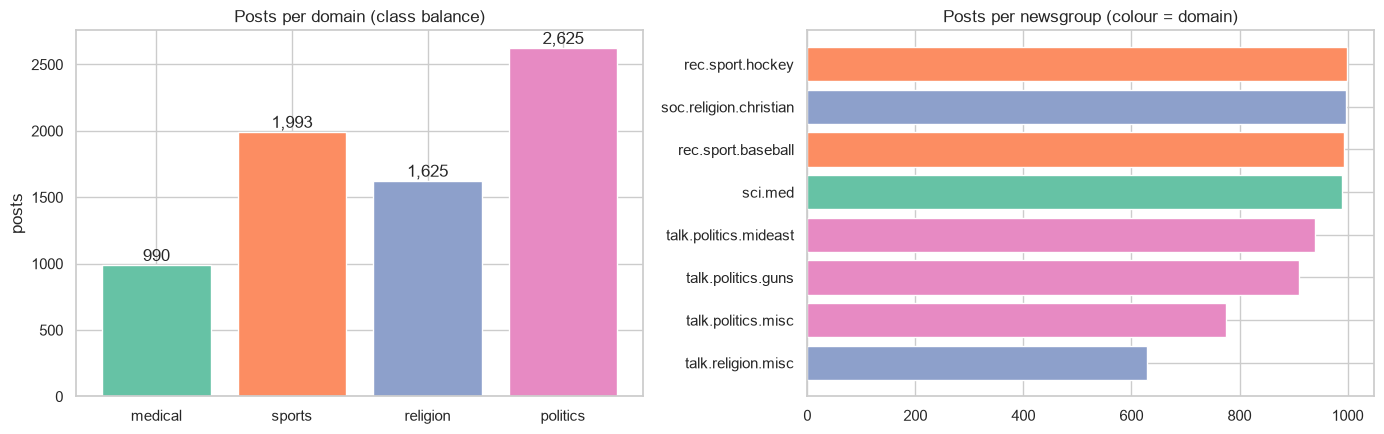

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
dom_counts = df['domain'].value_counts().reindex(DOMAINS)
axes[0].bar(dom_counts.index, dom_counts.values, color=[PALETTE[d] for d in DOMAINS])
axes[0].set_title('Posts per domain (class balance)')
axes[0].set_ylabel('posts')
for i, v in enumerate(dom_counts.values):
    axes[0].text(i, v + 30, f'{v:,}', ha='center')

ng = df.groupby(['newsgroup', 'domain']).size().reset_index(name='posts').sort_values('posts')
axes[1].barh(ng['newsgroup'], ng['posts'], color=[PALETTE[d] for d in ng['domain']])
axes[1].set_title('Posts per newsgroup (colour = domain)')
plt.tight_layout(); plt.show()

A raw post, showing why cleaning is required: header fields, an e-mail address, a quoted reply and a signature block surround the actual content.

In [4]:
print(df.loc[df['newsgroup'] == 'sci.med', 'raw'].iloc[3][:1500])

From: Lawrence Curcio <lc2b+@andrew.cmu.edu>
Subject: Analgesics with Diuretics

I sometimes see OTC preparations for muscle aches/back aches that
combine aspirin with a diuretic. The idea seems to be to reduce
inflammation by getting rid of fluid. Does this actually work? 

Thanks,
-Larry C. 



## 4. Preprocessing
Implementation of the cleaning steps described in §1.3:
1. `split_post`: separate the header from the body and keep only the `Subject`.
2. `clean_body`: drop quoted lines, attribution lines, signatures, ASCII art, e-mails and URLs.
3. `preprocess`: lowercase → tokenise → remove stop-words → lemmatise.

In [5]:
HEADER_SPLIT = re.compile(r'\n\s*\n')
QUOTE_LINE   = re.compile(r'^\s*(>|\|>|\||:)')
ATTRIB_LINE  = re.compile(r'(writes|wrote|says)\s*:\s*$|^\s*in article\s*<', re.I)
EMAIL        = re.compile(r'\S+@\S+')
URL          = re.compile(r'(https?://|www\.)\S+')

def split_post(raw):
    # Return (subject, body). Header = everything before the first blank line.
    parts = HEADER_SPLIT.split(raw, maxsplit=1)
    header, body = (parts[0], parts[1]) if len(parts) == 2 else ('', raw)
    m = re.search(r'^Subject:\s*(.*)$', header, re.M | re.I)
    subject = re.sub(r'^(re:\s*)+', '', m.group(1).strip(), flags=re.I) if m else ''
    return subject, body

def clean_body(body):
    kept = []
    for line in body.splitlines():
        s = line.strip()
        if s in ('--', '-- '):                       # signature delimiter: stop reading
            break
        if QUOTE_LINE.match(line) or ATTRIB_LINE.search(line):
            continue                                 # quoted reply / "X writes:"
        if s and sum(c.isalpha() for c in s) < 0.5 * len(s):
            continue                                 # separators, ASCII art, tables of numbers
        kept.append(s)
    text = ' '.join(kept)
    text = EMAIL.sub(' ', text)
    text = URL.sub(' ', text)
    return re.sub(r'\s+', ' ', text).strip()

lemmatizer = WordNetLemmatizer()
STOP = set(stopwords.words('english')) | {
    'writes', 'wrote', 'article', 'would', 'could', 'also', 'one', 'like', 'get', 'know',
    'think', 'say', 'said', 'make', 'well', 'much', 'even', 'way', 'thing', 'really',
    'see', 'go', 'going', 'want', 'may', 'might', 'must', 'many', 'use', 'used', 'anyone',
    'something', 'someone', 'etc', 'please', 'thanks', 'thank', 'yes', 'lot', 'got',
    'two', 'first', 'take', 'come', 'still', 'look', 'good', 'right', 'time', 'year',
    'mean', 'point', 'another', 'without', 'though', 'since', 'let', 'need', 'actually'}
TOKEN = re.compile(r'[a-z]+')

@lru_cache(maxsize=None)
def lemma(word):
    return lemmatizer.lemmatize(word)

def preprocess(text):
    # Text -> list of clean lemmatised tokens.
    out = []
    for tok in TOKEN.findall(text.lower()):
        if len(tok) < 3 or tok in STOP:
            continue
        lem = lemma(tok)
        if lem not in STOP and len(lem) >= 3:
            out.append(lem)
    return out

In [6]:
t0 = time.time()
df[['subject', 'body_raw']] = df['raw'].apply(lambda r: pd.Series(split_post(r)))
df['body'] = df['body_raw'].map(clean_body)
df['tokens'] = (df['subject'] + '. ' + df['body']).map(preprocess)
df['n_tokens'] = df['tokens'].map(len)
before = len(df)
df = df[df['n_tokens'] >= 5].reset_index(drop=True)      # drop empty posts (e.g. only quoted text)
print(f'Preprocessed in {time.time()-t0:.1f}s. Kept {len(df):,} of {before:,} posts '
      f'({before-len(df)} posts had < 5 content words after cleaning).')

ex = df[df['newsgroup'] == 'sci.med'].iloc[3]
print('\nSUBJECT :', ex['subject'])
print('BODY    :', ex['body'][:500])
print('TOKENS  :', ex['tokens'][:40])

Preprocessed in 6.3s. Kept 7,164 of 7,233 posts (69 posts had < 5 content words after cleaning).

SUBJECT : Analgesics with Diuretics
BODY    : I sometimes see OTC preparations for muscle aches/back aches that combine aspirin with a diuretic. The idea seems to be to reduce inflammation by getting rid of fluid. Does this actually work? Thanks, -Larry C.
TOKENS  : ['analgesic', 'diuretic', 'sometimes', 'otc', 'preparation', 'muscle', 'ache', 'back', 'ache', 'combine', 'aspirin', 'diuretic', 'idea', 'seems', 'reduce', 'inflammation', 'getting', 'rid', 'fluid', 'work', 'larry']


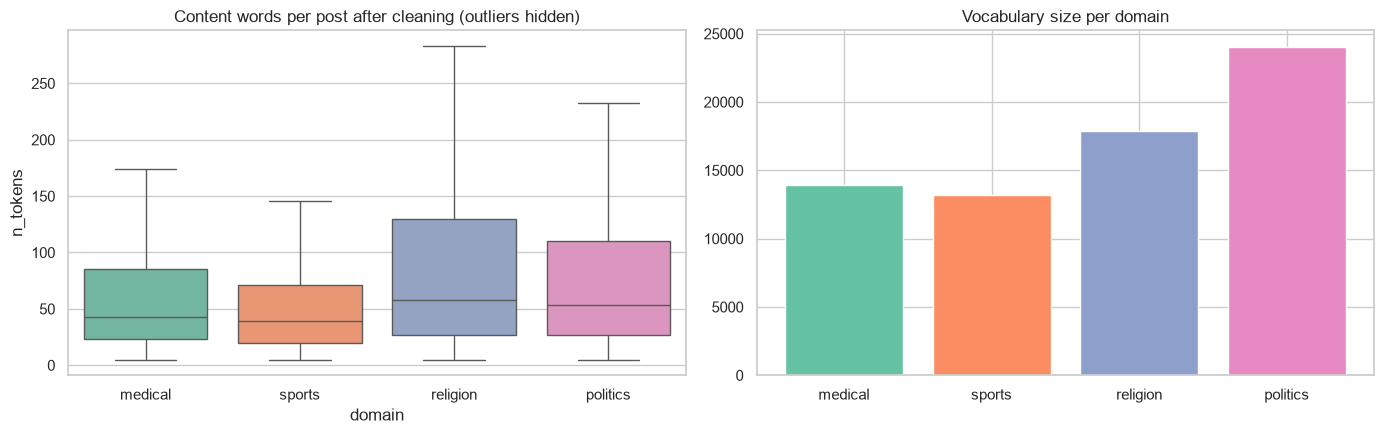

           mean   50%     max
domain                       
medical    97.4  43.0  2748.0
politics  123.3  53.0  4007.0
religion  112.9  57.5  3591.0
sports     64.1  39.0  5728.0


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=df, x='domain', y='n_tokens', order=DOMAINS, palette=PALETTE, ax=axes[0], showfliers=False)
axes[0].set_title('Content words per post after cleaning (outliers hidden)')
vocab_by_domain = {d: len(set(w for toks in df.loc[df.domain == d, 'tokens'] for w in toks)) for d in DOMAINS}
axes[1].bar(vocab_by_domain.keys(), vocab_by_domain.values(), color=[PALETTE[d] for d in DOMAINS])
axes[1].set_title('Vocabulary size per domain')
plt.tight_layout(); plt.show()
print(df.groupby('domain')['n_tokens'].describe()[['mean', '50%', 'max']].round(1))

**Most frequent words per domain.** Even before any modeling, the vocabularies are clearly different. This suggests that
keyword-based (bag-of-words) models should separate the domains well.

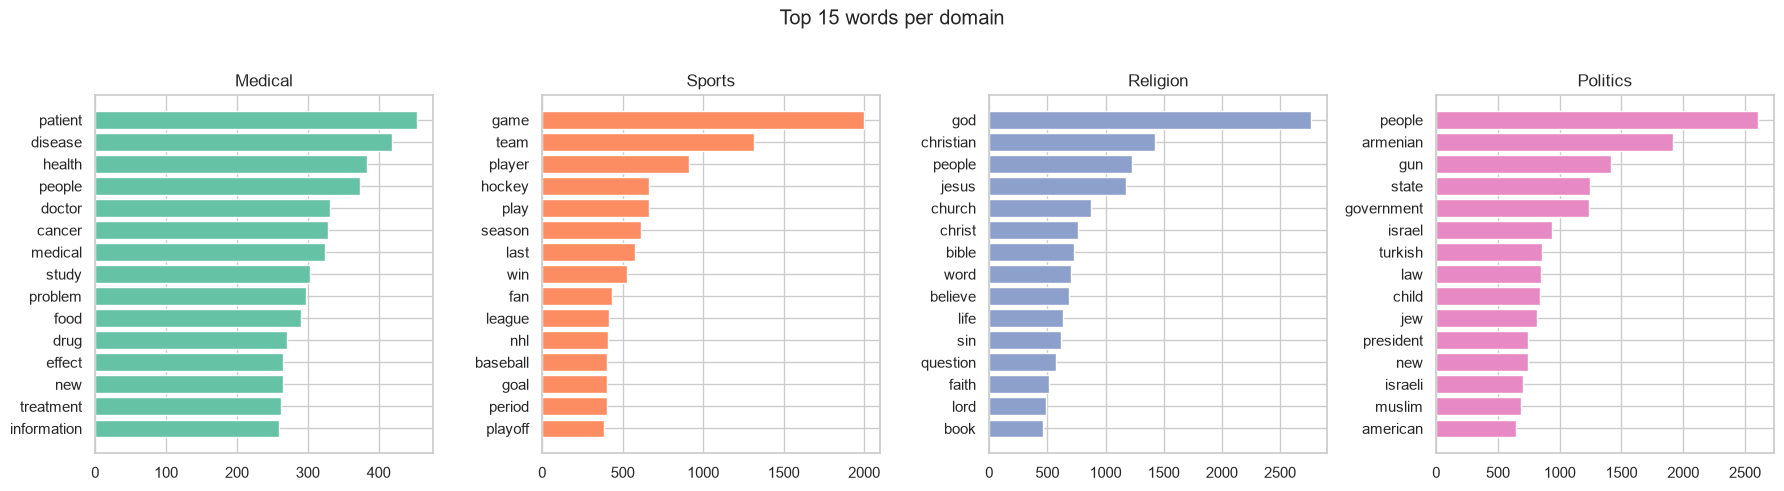

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
for ax, d in zip(axes, DOMAINS):
    top = pd.Series([w for toks in df.loc[df.domain == d, 'tokens'] for w in toks]).value_counts().head(15)
    ax.barh(top.index[::-1], top.values[::-1], color=PALETTE[d])
    ax.set_title(d.capitalize())
plt.suptitle('Top 15 words per domain', y=1.02); plt.tight_layout(); plt.show()

## 5. Evaluation Design: Splits and Three-Sentence Chunks
* **Document-level split** 70 / 15 / 15 (train / validation / test), stratified by domain.
* **Chunks:** each validation/test post body is split into sentences (NLTK Punkt) and grouped into consecutive windows of **three
  sentences**, which mirrors the real input. Chunks with fewer than 5 content words are dropped, and at most 5 chunks are taken
  per post so that very long posts do not dominate.
* **Other data:** posts from unrelated newsgroups are cleaned the same way and chunked identically.

In [9]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df['domain'], random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df['domain'], random_state=SEED)
print(f'train {len(train_df):,} | validation {len(val_df):,} | test {len(test_df):,} posts')

def make_chunks(body, rng, n=3, max_chunks=5, min_tokens=5):
    sents = [s for s in sent_tokenize(body) if len(s.split()) >= 3]
    chunks = [' '.join(sents[i:i + n]) for i in range(0, len(sents), n)]
    chunks = [c for c in chunks if len(preprocess(c)) >= min_tokens]
    if len(chunks) > max_chunks:
        chunks = rng.sample(chunks, max_chunks)
    return chunks

def chunk_frame(frame):
    rng = random.Random(SEED)
    out = [{'label': r.domain, 'source': r.newsgroup, 'text': c}
           for r in frame.itertuples() for c in make_chunks(r.body, rng)]
    return pd.DataFrame(out)

def load_other(split):
    rows = []
    for g in sorted((DATA / 'outside' / 'other_20ng' / split).iterdir()):
        for f in sorted(g.iterdir()):
            _, body = split_post(read_file(f))
            rows.append({'domain': 'other', 'newsgroup': g.name, 'body': clean_body(body)})
    return pd.DataFrame(rows)

val_chunks, test_chunks = chunk_frame(val_df), chunk_frame(test_df)
other_tune_chunks, other_test_chunks = chunk_frame(load_other('tune')), chunk_frame(load_other('test'))

sizes = pd.DataFrame({
    'validation (in-domain)': val_chunks['label'].value_counts(),
    'test (in-domain)': test_chunks['label'].value_counts()}).reindex(DOMAINS)
sizes.loc['other'] = [len(other_tune_chunks), len(other_test_chunks)]
display(sizes.rename(columns={'validation (in-domain)': 'validation chunks (Other = tune groups)',
                              'test (in-domain)': 'test chunks (Other = unseen groups)'}))
print('Other tune groups:', sorted(other_tune_chunks.source.unique()))
print('Other test groups:', sorted(other_test_chunks.source.unique()))
print('\nExample 3-sentence test chunk:\n ', test_chunks.sample(1, random_state=1)['text'].iloc[0])

train 5,014 | validation 1,075 | test 1,075 posts


,validation chunks (Other = tune groups),test chunks (Other = unseen groups)
label,,
medical,368,389
sports,682,640
religion,680,728
politics,1032,1119
other,983,834


Other tune groups: ['comp.graphics', 'comp.windows.x', 'rec.autos']
Other test groups: ['misc.forsale', 'rec.motorcycles', 'sci.electronics', 'sci.space']

Example 3-sentence test chunk:
  My opinion(for what it's worth) is that 40 x-rays is *way* too many. Guidleines have been set on the number of dental x-rays and chest x-rays that one should have over a given period of time because of all the environmental factors that can cause cancer in humans, ionizing radiation is one of the most potent(splits DNA and causes hydroxyl free radical formation in tissue cells). Ultasound(like that used in seeing the fetus in the uterus) has been shown to be extremely good at picking up tumors in the prostate and gallstones in the gallbladder.


## 6. Unsupervised Topic Modeling

### 6.1 LDA: choosing the number of topics with coherence
The Bag-of-Words dictionary keeps words that appear in at least 5 training posts and in at most 50% of them, since very rare and
very common words carry little topic information. LDA is trained for several values of $K$, and the $C_v$ coherence of each model is measured.

In [10]:
dictionary = Dictionary(train_df['tokens'])
dictionary.filter_extremes(no_below=5, no_above=0.5, keep_n=15000)
bow_train = [dictionary.doc2bow(t) for t in train_df['tokens']]
print(f'Dictionary: {len(dictionary):,} terms, {len(bow_train):,} training documents')

def train_lda(k):
    return LdaModel(bow_train, id2word=dictionary, num_topics=k, passes=10, iterations=100,
                    alpha='auto', eta='auto', chunksize=2000, random_state=SEED)

K_GRID = [4, 6, 8, 10, 12, 16, 20]
lda_models, coherence = {}, {}
t0 = time.time()
for k in K_GRID:
    lda_models[k] = train_lda(k)
    coherence[k] = CoherenceModel(model=lda_models[k], texts=train_df['tokens'].tolist(),
                                  dictionary=dictionary, coherence='c_v', processes=1).get_coherence()
    print(f'K={k:>2}  coherence C_v = {coherence[k]:.4f}')
print(f'({time.time()-t0:.0f}s)')

Dictionary: 9,600 terms, 5,014 training documents


K= 4  coherence C_v = 0.5743


K= 6  coherence C_v = 0.5694


K= 8  coherence C_v = 0.5628


K=10  coherence C_v = 0.5663


K=12  coherence C_v = 0.5396


K=16  coherence C_v = 0.5884


K=20  coherence C_v = 0.5727
(157s)


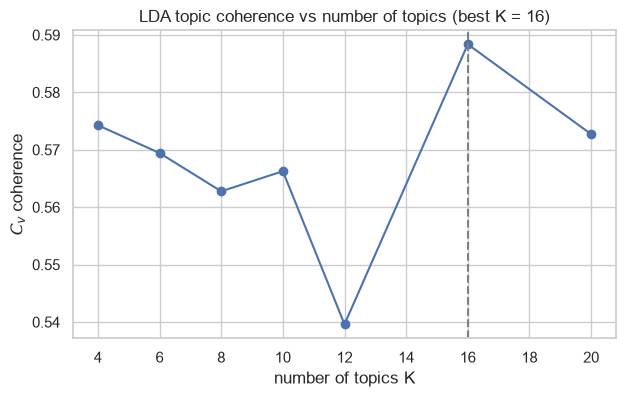

In [11]:
BEST_K = max(coherence, key=coherence.get)
lda = lda_models[BEST_K]

plt.figure(figsize=(7, 4))
plt.plot(list(coherence), list(coherence.values()), 'o-', color='#4c72b0')
plt.axvline(BEST_K, ls='--', color='grey')
plt.title(f'LDA topic coherence vs number of topics (best K = {BEST_K})')
plt.xlabel('number of topics K'); plt.ylabel('$C_v$ coherence'); plt.show()

### 6.2 What the LDA topics contain, and how they map to domains
Each topic is mapped to the domain where it has the highest average share (§1.5). The heat-map shows that mapping:
each row is a topic, and a dark cell means the topic is used mostly by that domain's documents.

,top words,mapped domain
topic,,
0,"game, team, player, hockey, season, fan, win, last, baseball, league",sports
1,"doctor, patient, help, food, effect, problem, medical, cause, msg, vitamin",medical
2,"health, drug, study, disease, aid, rate, national, hiv, woman, risk",medical
3,"israel, israeli, jew, arab, jewish, palestinian, war, state, country, peace",politics
4,"president, job, clinton, program, people, work, school, tax, myers, secretary",politics
5,"hit, run, pitcher, base, pitch, better, ball, hitter, mormon, pitching",sports
6,"armenian, university, cancer, professor, new, population, russian, istanbul, ottoman, percent",medical
7,"armenian, azerbaijan, azeri, people, armenia, village, killed, soldier, massacre, child",politics
8,"christian, book, gay, post, life, new, read, morality, objective, christianity",religion


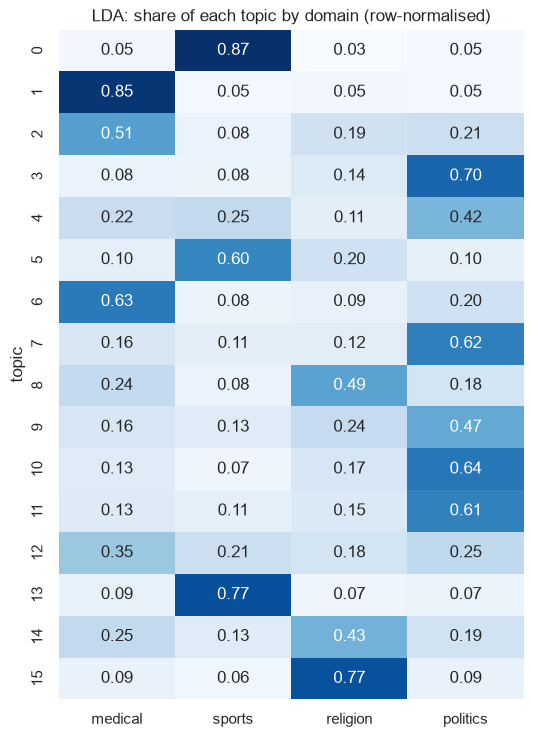

In [12]:
def lda_theta(model, bows):
    # Document-topic matrix theta (n_docs x K).
    theta = np.zeros((len(bows), model.num_topics))
    for i, b in enumerate(bows):
        for k, p in model.get_document_topics(b, minimum_probability=0):
            theta[i, k] = p
    return theta

def topic_domain_matrix(theta, labels):
    labels = np.asarray(labels)
    M = np.vstack([theta[labels == d].mean(axis=0) for d in DOMAINS]).T     # K x 4
    return pd.DataFrame(M, columns=DOMAINS)

theta_train = lda_theta(lda, bow_train)
lda_map_df = topic_domain_matrix(theta_train, train_df['domain'])
lda_topic2domain = lda_map_df.idxmax(axis=1)

lda_topics = pd.DataFrame({
    'top words': [', '.join(w for w, _ in lda.show_topic(k, topn=10)) for k in range(BEST_K)],
    'mapped domain': lda_topic2domain.values})
lda_topics.index.name = 'topic'
display(lda_topics)

plt.figure(figsize=(6, 0.45 * BEST_K + 1.5))
sns.heatmap(lda_map_df.div(lda_map_df.sum(axis=1), axis=0), annot=True, fmt='.2f', cmap='Blues', cbar=False)
plt.title('LDA: share of each topic by domain (row-normalised)'); plt.ylabel('topic'); plt.show()

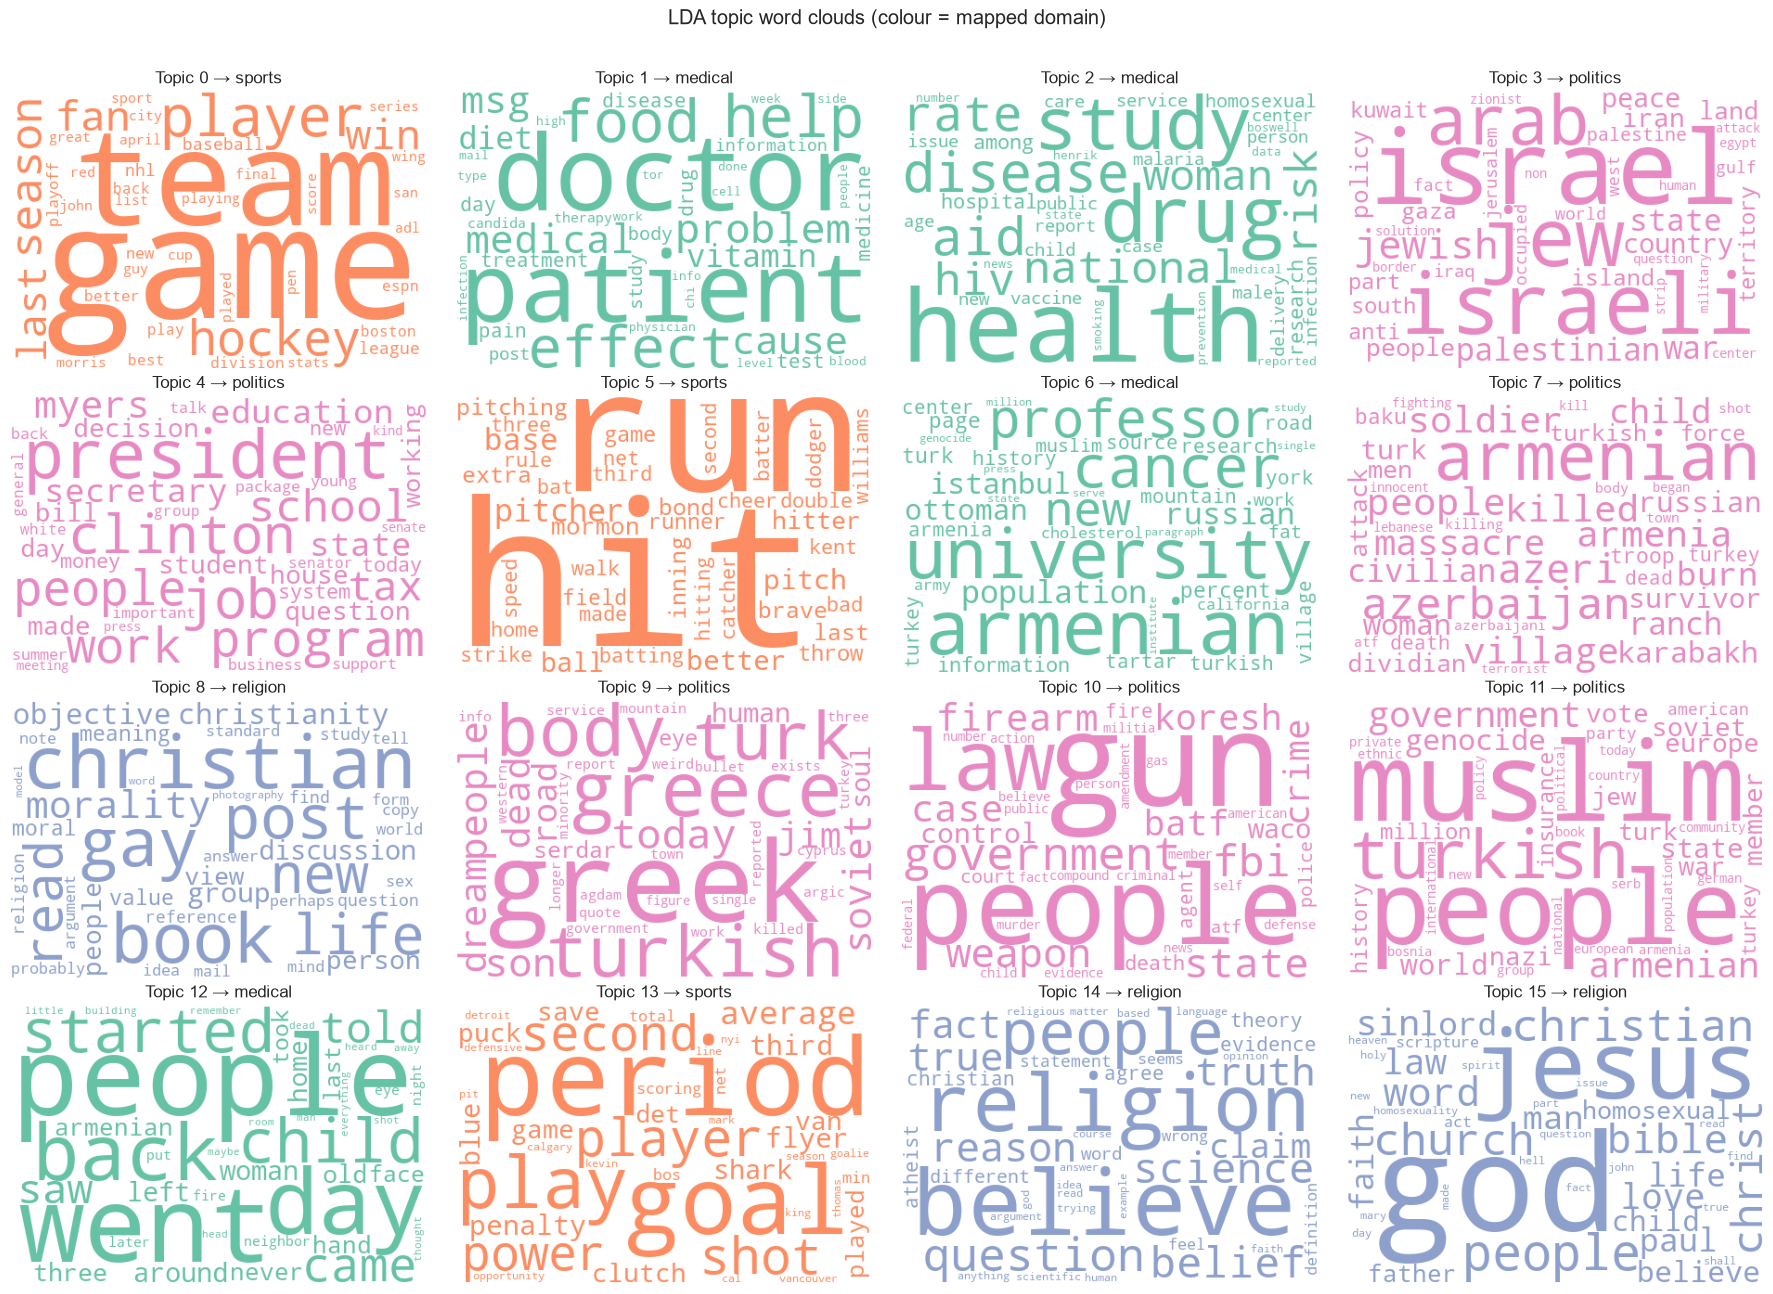

In [13]:
cols = 4
rows_ = int(np.ceil(BEST_K / cols))
fig, axes = plt.subplots(rows_, cols, figsize=(4.5 * cols, 3.2 * rows_))
for k, ax in enumerate(axes.flat):
    ax.axis('off')
    if k >= BEST_K:
        continue
    freqs = dict(lda.show_topic(k, topn=40))
    colour = PALETTE[lda_topic2domain[k]]
    hexc = '#%02x%02x%02x' % tuple(int(255 * c) for c in colour)
    wc = WordCloud(width=450, height=300, background_color='white', random_state=SEED,
                   color_func=lambda *a, **kw: hexc).generate_from_frequencies(freqs)
    ax.imshow(wc); ax.set_title(f'Topic {k} → {lda_topic2domain[k]}')
plt.suptitle('LDA topic word clouds (colour = mapped domain)', y=1.01); plt.tight_layout(); plt.show()

### 6.3 Interactive topic map (pyLDAvis)
Each circle is a topic. Its area is the topic's prevalence, and the distance between circles reflects how different the topics' word
distributions are (Sievert & Shirley, 2014). Select a topic to see its most relevant words. Topics from the same domain sit close together.

In [14]:
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis
pyLDAvis.enable_notebook()
lda_vis = gensimvis.prepare(lda, bow_train, dictionary, sort_topics=False, mds='mmds')
lda_vis

PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
0      0.325862  0.120423       1        1   9.059621
1      0.213214 -0.241796       2        1   6.137467
2     -0.304287 -0.261408       3        1   2.852372
3     -0.154737  0.033091       4        1   5.357398
4      0.183612 -0.014786       5        1   5.245882
5      0.368550 -0.083117       6        1   2.960120
6      0.060692  0.378228       7        1   3.684495
7     -0.323658  0.165620       8        1   3.130055
8     -0.044314 -0.314006       9        1   5.384734
9      0.164536  0.253041      10        1   2.366723
10     0.012744 -0.053806      11        1  14.926264
11    -0.038440  0.178575      12        1   6.776134
12    -0.305780 -0.026527      13        1   7.696690
13    -0.177700  0.388199      14        1   4.170107
14     0.089706 -0.336640      15        1   5.503213
15    -0.070002 -0.185091      16        1  14.748726, topic_info=          Term         Freq        Total Category  logprob  loglift
574        god  2054.000000  2054.000000  Default  30.0000  30.0000
2623  armenian  1453.000000  1453.000000  Default  29.0000  29.0000
295       game  1526.000000  1526.000000  Default  28.0000  28.0000
249     israel   781.000000   781.000000  Default  27.0000  27.0000
336       team  1010.000000  1010.000000  Default  26.0000  26.0000
...        ...          ...          ...      ...      ...      ...
1403     issue   202.861483   564.027970  Topic16  -5.8151   0.8914
323   question   217.520884  1041.844605  Topic16  -5.7453   0.3476
115       part   203.997141   760.390014  Topic16  -5.8095   0.5983
14        fact   207.261212   930.590467  Topic16  -5.7936   0.4122
455        day   202.286377  1112.749721  Topic16  -5.8179   0.2091

[1119 rows x 6 columns], token_table=      Topic      Freq        Term
term                             
945       1  0.985581         abc
644       9  0.045257    absolute
644      12  0.063360    absolute
644      15  0.778422    absolute
644      16  0.108617    absolute
...     ...       ...         ...
342      14  0.101214       young
342      16  0.137361       young
570      12  0.986637  yugoslavia
4645      4  0.989775     zionism
2781      4  0.991506     zionist

[3638 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16])

### 6.4 NMF topics
NMF is fitted on a TF-IDF matrix with the same number of topics, so the two topic models can be compared directly.

In [15]:
train_df['text_pp'] = train_df['tokens'].str.join(' ')
nmf_vec = TfidfVectorizer(token_pattern=r'\S+', min_df=5, max_df=0.5, max_features=15000)
X_nmf = nmf_vec.fit_transform(train_df['text_pp'])
nmf = NMF(n_components=BEST_K, init='nndsvda', max_iter=500, random_state=SEED)
W_train = nmf.fit_transform(X_nmf)
nmf_words = np.array(nmf_vec.get_feature_names_out())

def normalise_rows(W):
    s = W.sum(axis=1, keepdims=True)
    return np.divide(W, s, out=np.full_like(W, 1 / W.shape[1]), where=s > 0)

nmf_map_df = topic_domain_matrix(normalise_rows(W_train), train_df['domain'])
nmf_topic2domain = nmf_map_df.idxmax(axis=1)
nmf_topics = pd.DataFrame({
    'top words': [', '.join(nmf_words[np.argsort(h)[::-1][:10]]) for h in nmf.components_],
    'mapped domain': nmf_topic2domain.values})
nmf_topics.index.name = 'topic'
display(nmf_topics)

,top words,mapped domain
topic,,
0,"drug, doctor, patient, effect, medical, disease, help, problem, treatment, information",medical
1,"team, run, hit, pitcher, win, morris, brave, pitching, last, jay",sports
2,"armenian, turkish, armenia, turk, soviet, genocide, turkey, azeri, russian, azerbaijan",politics
3,"god, jesus, sin, christ, hell, lord, love, bible, heaven, life",religion
4,"israel, israeli, arab, jew, palestinian, peace, lebanon, gaza, state, lebanese",politics
5,"fbi, batf, koresh, waco, fire, child, compound, agent, gas, warrant",politics
6,"gun, control, firearm, crime, criminal, weapon, buy, handgun, police, law",politics
7,"game, espn, hockey, baseball, fan, pen, cap, coverage, playoff, night",sports
8,"homosexual, gay, study, percentage, homosexuality, new, men, sex, sexual, people",politics


### 6.5 Topic models as classifiers
A three-sentence chunk is turned into topic proportions. The proportions of all topics mapped to the same domain are summed, and the
domain with the largest total wins. This is evaluated on the **validation chunks** (closed-set, 4 domains).

In [16]:
def topic_scores(theta, topic2domain):
    # Sum topic proportions per mapped domain -> (n x 4) score matrix.
    S = np.zeros((theta.shape[0], len(DOMAINS)))
    for k, d in topic2domain.items():
        S[:, DOMAINS.index(d)] += theta[:, k]
    return S

def lda_scores(texts):
    bows = [dictionary.doc2bow(preprocess(t)) for t in texts]
    return topic_scores(lda_theta(lda, bows), lda_topic2domain)

def nmf_scores(texts):
    W = nmf.transform(nmf_vec.transform([' '.join(preprocess(t)) for t in texts]))
    return topic_scores(normalise_rows(W), nmf_topic2domain)

topic_results = {}
for name, fn in [('LDA (topic → domain)', lda_scores), ('NMF (topic → domain)', nmf_scores)]:
    pred = np.array(DOMAINS)[fn(val_chunks['text']).argmax(axis=1)]
    topic_results[name] = {'accuracy': accuracy_score(val_chunks['label'], pred),
                           'macro-F1': f1_score(val_chunks['label'], pred, average='macro')}
display(pd.DataFrame(topic_results).T.round(3))

,accuracy,macro-F1
LDA (topic → domain),0.732,0.720
NMF (topic → domain),0.811,0.802


## 7. Supervised Classification
TF-IDF features use unigrams and bigrams, sublinear TF and L2 normalisation, and are fitted on the **training posts only**. Each model is
scored on the **validation chunks**. The hybrid *LDA features → Logistic Regression* model is included for comparison.

In [17]:
vectorizer = TfidfVectorizer(token_pattern=r'\S+', ngram_range=(1, 2), min_df=2, max_df=0.5,
                             sublinear_tf=True, max_features=100_000)
X_train = vectorizer.fit_transform(train_df['text_pp'])
y_train = train_df['domain'].values
print('TF-IDF matrix:', X_train.shape)

def tfidf(texts):
    return vectorizer.transform([' '.join(preprocess(t)) for t in texts])

X_val = tfidf(val_chunks['text'])
y_val = val_chunks['label'].values

models = {
    'Multinomial Naive Bayes': MultinomialNB(alpha=0.1, fit_prior=False),
    'Logistic Regression': LogisticRegression(C=10, max_iter=3000, class_weight='balanced'),
    'Linear SVM (Platt-calibrated)': CalibratedClassifierCV(
        LinearSVC(C=0.5, class_weight='balanced'), cv=5, method='sigmoid'),
}
results = {}
for name, model in models.items():
    t0 = time.time()
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    results[name] = {'accuracy': accuracy_score(y_val, pred),
                     'macro-F1': f1_score(y_val, pred, average='macro'),
                     'train time (s)': time.time() - t0}

# Hybrid: LDA topic proportions as features
hybrid = LogisticRegression(C=10, max_iter=3000, class_weight='balanced').fit(theta_train, y_train)
theta_val = lda_theta(lda, [dictionary.doc2bow(preprocess(t)) for t in val_chunks['text']])
pred = hybrid.predict(theta_val)
results[f'Hybrid: LDA ({BEST_K} topics) → LogReg'] = {
    'accuracy': accuracy_score(y_val, pred), 'macro-F1': f1_score(y_val, pred, average='macro'), 'train time (s)': np.nan}
for name, r in topic_results.items():
    results[name] = {**r, 'train time (s)': np.nan}

comparison = pd.DataFrame(results).T.sort_values('macro-F1', ascending=False)
display(comparison.style.format({'accuracy': '{:.3f}', 'macro-F1': '{:.3f}', 'train time (s)': '{:.1f}'})
        .background_gradient(subset=['macro-F1'], cmap='Greens'))

TF-IDF matrix: (5014, 66918)


,accuracy,macro-F1,train time (s)
Multinomial Naive Bayes,0.892,0.889,0.0
Linear SVM (Platt-calibrated),0.874,0.871,0.4
Logistic Regression,0.870,0.867,0.8
NMF (topic → domain),0.811,0.802,nan
Hybrid: LDA (16 topics) → LogReg,0.770,0.760,nan
LDA (topic → domain),0.732,0.720,nan


Selected model (highest validation macro-F1): Multinomial Naive Bayes


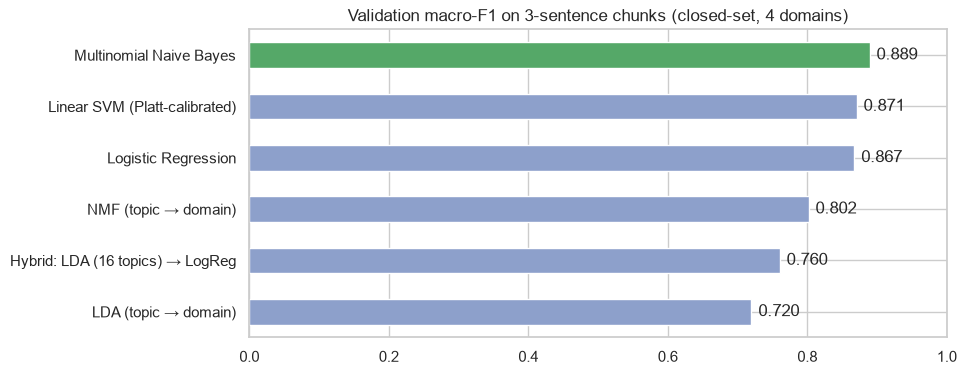

In [18]:
supervised_only = comparison.loc[[n for n in models]]
BEST_NAME = supervised_only['macro-F1'].idxmax()
best_model = models[BEST_NAME]
print(f'Selected model (highest validation macro-F1): {BEST_NAME}')

fig, ax = plt.subplots(figsize=(9, 4))
comparison['macro-F1'][::-1].plot.barh(ax=ax, color=['#55a868' if n == BEST_NAME else '#8da0cb'
                                                     for n in comparison.index[::-1]])
ax.set_xlim(0, 1); ax.set_title('Validation macro-F1 on 3-sentence chunks (closed-set, 4 domains)')
for i, v in enumerate(comparison['macro-F1'][::-1]):
    ax.text(v + 0.01, i, f'{v:.3f}', va='center')
plt.show()

**Most indicative words per class** (largest positive weights of the selected linear model). These are the words that pull a text towards each domain.
Only terms that occur in at least 20 training posts are listed, because one-off words (typos, names from a single thread) otherwise dominate the ranking.

In [19]:
def class_weights(model):
    # Return a (n_classes x n_features) weight matrix for any of the linear models.
    if hasattr(model, 'calibrated_classifiers_'):
        return np.mean([c.estimator.coef_ for c in model.calibrated_classifiers_], axis=0)
    if hasattr(model, 'feature_log_prob_'):
        return model.feature_log_prob_ - model.feature_log_prob_.mean(axis=0)
    return model.coef_

WEIGHTS = class_weights(best_model)
FEATURES = np.array(vectorizer.get_feature_names_out())
MODEL_CLASSES = list(best_model.classes_)
doc_freq = np.asarray((X_train > 0).sum(axis=0)).ravel()
common = doc_freq >= 20
top_feats = pd.DataFrame({c: FEATURES[common][np.argsort(WEIGHTS[i][common])[::-1][:15]]
                          for i, c in enumerate(MODEL_CLASSES)})
display(top_feats[DOMAINS])

,medical,sports,religion,politics
0,photography,hockey,jesus,israeli
1,krillean,nhl,sin,arab
2,krillean photography,playoff,scripture,atf burn
3,msg sensitivity,espn,christianity,ranch
4,sensitivity superstition,player,verse,dividian
5,candida,bruin,christian,burn dividian
6,infection,hitter,bible,dividian ranch
7,antibiotic,season,christian morality,israel
8,diet,coach,biblical,armenian
9,migraine,phillies,clh,atf


## 8. The *Other* Class: Tuning the Confidence Threshold τ
The selected model gives class probabilities. If the highest probability is below τ, the text is labelled **Other**.
τ is chosen to maximise **5-class macro-F1** on the tuning set: validation in-domain chunks plus *Other* chunks from
`comp.graphics`, `comp.windows.x` and `rec.autos`.

Best threshold τ = 0.64  (tuning macro-F1 = 0.793)


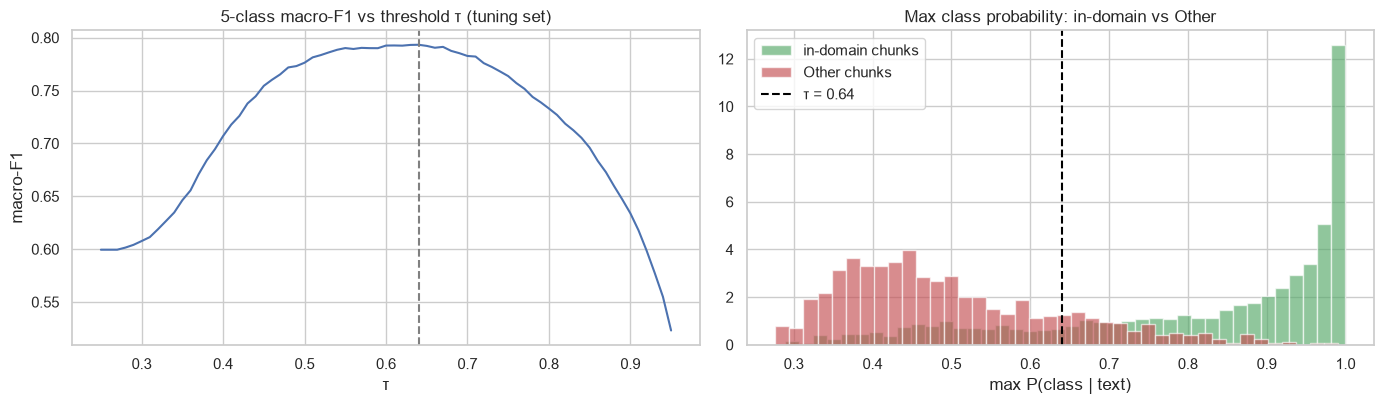

In [20]:
def predict_with_threshold(P, tau):
    labels = np.array(MODEL_CLASSES)[P.argmax(axis=1)]
    return np.where(P.max(axis=1) < tau, 'other', labels)

P_tune = np.vstack([best_model.predict_proba(X_val), best_model.predict_proba(tfidf(other_tune_chunks['text']))])
y_tune = np.concatenate([y_val, ['other'] * len(other_tune_chunks)])

taus = np.round(np.arange(0.25, 0.96, 0.01), 2)
tau_scores = [f1_score(y_tune, predict_with_threshold(P_tune, t), labels=CLASSES, average='macro') for t in taus]
TAU = float(taus[int(np.argmax(tau_scores))])
print(f'Best threshold τ = {TAU:.2f}  (tuning macro-F1 = {max(tau_scores):.3f})')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(taus, tau_scores, color='#4c72b0')
axes[0].axvline(TAU, ls='--', color='grey')
axes[0].set_title('5-class macro-F1 vs threshold τ (tuning set)')
axes[0].set_xlabel('τ'); axes[0].set_ylabel('macro-F1')

maxp = P_tune.max(axis=1)
in_dom = y_tune != 'other'
axes[1].hist(maxp[in_dom], bins=40, alpha=.65, density=True, label='in-domain chunks', color='#55a868')
axes[1].hist(maxp[~in_dom], bins=40, alpha=.65, density=True, label='Other chunks', color='#c44e52')
axes[1].axvline(TAU, ls='--', color='black', label=f'τ = {TAU:.2f}')
axes[1].set_title('Max class probability: in-domain vs Other'); axes[1].set_xlabel('max P(class | text)')
axes[1].legend(); plt.tight_layout(); plt.show()

The histogram explains why the method works. In-domain texts usually get a confident probability close to 1, while texts from
unrelated subjects get a flatter distribution with a low maximum. The overlap between the two histograms is where the remaining errors come from.

## 9. Final Evaluation on Held-out Data
Everything below is measured **once**, on data that played no part in training or tuning:
* **test chunks**: 3-sentence chunks of the 15% held-out posts of the four domains;
* **unseen *Other* chunks**: posts from `sci.space`, `misc.forsale`, `rec.motorcycles` and `sci.electronics`. These are subjects that were
  **never** used, not even for tuning τ.

In [21]:
X_test = tfidf(test_chunks['text'])
y_test = test_chunks['label'].values

# (a) closed-set: four domains only, no threshold
closed_pred = best_model.predict(X_test)
print('(a) CLOSED-SET (4 domains, no Other)')
print(f'    accuracy = {accuracy_score(y_test, closed_pred):.3f}   macro-F1 = {f1_score(y_test, closed_pred, average="macro"):.3f}\n')

# (b) open-set: 5 classes with the threshold
P_final = np.vstack([best_model.predict_proba(X_test), best_model.predict_proba(tfidf(other_test_chunks['text']))])
y_final = np.concatenate([y_test, ['other'] * len(other_test_chunks)])
final_pred = predict_with_threshold(P_final, TAU)
print(f'(b) OPEN-SET (5 classes, τ = {TAU:.2f})')
print(f'    accuracy = {accuracy_score(y_final, final_pred):.3f}   macro-F1 = {f1_score(y_final, final_pred, labels=CLASSES, average="macro"):.3f}\n')
print(classification_report(y_final, final_pred, labels=CLASSES, digits=3))

(a) CLOSED-SET (4 domains, no Other)
    accuracy = 0.894   macro-F1 = 0.894

(b) OPEN-SET (5 classes, τ = 0.64)
    accuracy = 0.778   macro-F1 = 0.793

              precision    recall  f1-score   support

     medical      0.843     0.720     0.777       389
      sports      0.962     0.867     0.912       640
    religion      0.924     0.750     0.828       728
    politics      0.873     0.743     0.803      1119
       other      0.535     0.807     0.643       834

    accuracy                          0.778      3710
   macro avg      0.827     0.777     0.793      3710
weighted avg      0.819     0.778     0.788      3710



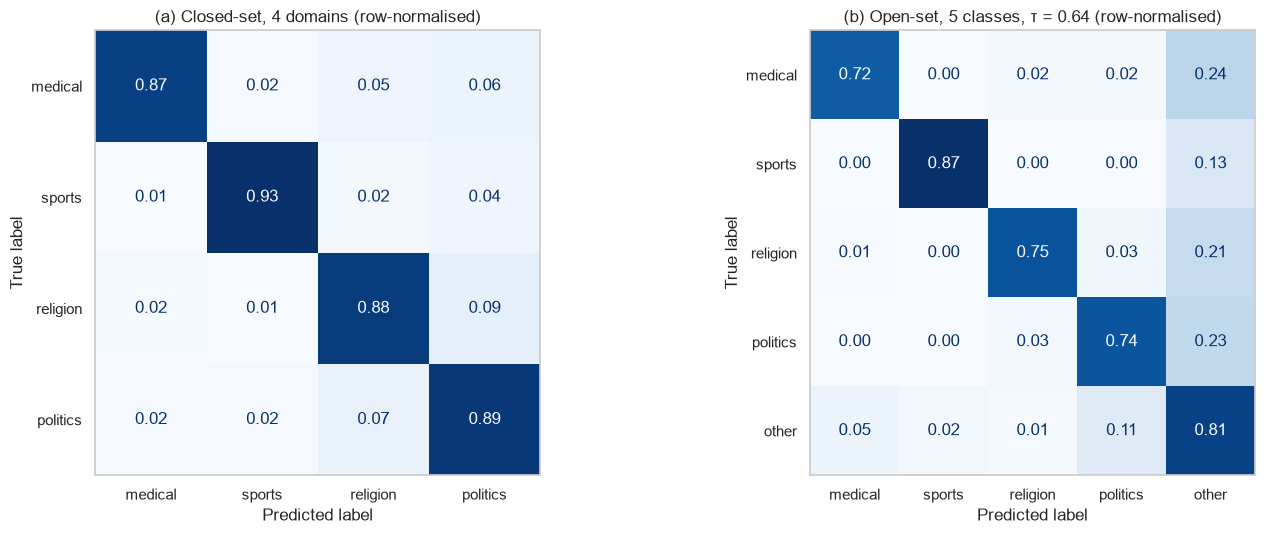

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, closed_pred, labels=DOMAINS, normalize='true'),
                       display_labels=DOMAINS).plot(ax=axes[0], cmap='Blues', values_format='.2f', colorbar=False)
axes[0].set_title('(a) Closed-set, 4 domains (row-normalised)')
ConfusionMatrixDisplay(confusion_matrix(y_final, final_pred, labels=CLASSES, normalize='true'),
                       display_labels=CLASSES).plot(ax=axes[1], cmap='Blues', values_format='.2f', colorbar=False)
axes[1].set_title(f'(b) Open-set, 5 classes, τ = {TAU:.2f} (row-normalised)')
for ax in axes:
    ax.grid(False)
plt.tight_layout(); plt.show()

In [23]:
other_pred = final_pred[len(y_test):]
rej = (pd.DataFrame({'newsgroup': other_test_chunks['source'], 'predicted': other_pred})
         .groupby('newsgroup')['predicted'].value_counts(normalize=True).unstack(fill_value=0)
         .reindex(columns=CLASSES, fill_value=0))
print('Where do chunks from UNSEEN unrelated newsgroups end up? (row = source newsgroup)')
display(rej.style.format('{:.1%}').background_gradient(cmap='Reds', axis=None))

Where do chunks from UNSEEN unrelated newsgroups end up? (row = source newsgroup)


predicted,medical,sports,religion,politics,other
newsgroup,,,,,
misc.forsale,4.3%,2.7%,1.1%,4.9%,87.0%
rec.motorcycles,1.5%,3.4%,1.5%,9.2%,84.5%
sci.electronics,9.6%,2.3%,0.9%,6.9%,80.3%
sci.space,5.3%,0.9%,0.9%,20.4%,72.6%


## 10. Testing with Outside Data: Hand-written Texts
The 30 texts in `data/outside/handmade/<class>/` were written for this coursework: six 3-sentence texts per class, in modern
language and about modern events. None of them comes from the training corpora. Some are **deliberately ambiguous**:
* `medical_06`: a footballer's knee surgery (medical vocabulary in a sports context);
* `religion_06`: a church council debating public funding of religious schools (religion and politics);
* `politics_06`: a court ruling on surveillance law (politics with legal vocabulary);
* `sports_06`: a coach being fired (sport with employment and business vocabulary).

For each text the table shows the final prediction, the model's confidence, the prediction of the unsupervised LDA topic model, and
the **key words** that pushed the classifier towards its decision (TF-IDF value × class weight).

In [24]:
hand = pd.DataFrame([{'id': f.stem, 'label': c, 'text': f.read_text(encoding='utf-8').strip()}
                     for c in CLASSES for f in sorted((DATA / 'outside' / 'handmade' / c).glob('*.txt'))])

def explain(text, cls, top=5):
    # Words with the largest positive contribution to class `cls`.
    x = tfidf([text]).toarray()[0]
    contrib = x * WEIGHTS[MODEL_CLASSES.index(cls)]
    idx = [i for i in np.argsort(contrib)[::-1][:top] if contrib[i] > 0]
    return ', '.join(FEATURES[idx])

P_hand = best_model.predict_proba(tfidf(hand['text']))
hand['predicted'] = predict_with_threshold(P_hand, TAU)
hand['confidence'] = P_hand.max(axis=1)
hand['LDA topic model'] = np.array(DOMAINS)[lda_scores(hand['text']).argmax(axis=1)]
hand['key words'] = [explain(t, MODEL_CLASSES[p.argmax()]) for t, p in zip(hand['text'], P_hand)]
hand['correct'] = np.where(hand['label'] == hand['predicted'], '✔', '✘')

acc = (hand['label'] == hand['predicted']).mean()
print(f'Hand-written outside texts: {acc:.1%} correct ({(hand.label == hand.predicted).sum()}/{len(hand)}), '
      f'macro-F1 = {f1_score(hand.label, hand.predicted, labels=CLASSES, average="macro"):.3f}')
display(hand[['id', 'label', 'predicted', 'correct', 'confidence', 'LDA topic model', 'key words']]
        .style.format({'confidence': '{:.2f}'})
        .apply(lambda r: ['background-color: #fde0dd' if r['correct'] == '✘' else '' for _ in r], axis=1))

Hand-written outside texts: 100.0% correct (30/30), macro-F1 = 1.000


,id,label,predicted,correct,confidence,LDA topic model,key words
0,medical_01,medical,medical,✔,0.89,medical,"ecg, mild, patient, pain, doctor"
1,medical_02,medical,medical,✔,1.00,medical,"diabetes, kidney, diet, sugar, help patient"
2,medical_03,medical,medical,✔,0.99,medical,"clinical, clinical trial, side effect, sore, vaccine"
3,medical_04,medical,medical,✔,1.00,medical,"migraine, headache, neurologist, chronic, beta blocker"
4,medical_05,medical,medical,✔,1.00,medical,"antibiotic, infection, bacteria, viral, fluid"
5,medical_06,medical,medical,✔,0.73,medical,"repaired, surgery, surgeon, physiotherapy, recovery"
6,sports_01,sports,sports,✔,0.97,sports,"win, scored, league, home team, team"
7,sports_02,sports,sports,✔,1.00,sports,"game, batter, pitcher, shutout, straight win"
8,sports_03,sports,sports,✔,0.71,sports,"scored, win, series, final day, opening"
9,sports_04,sports,sports,✔,1.00,sports,"hockey, overtime, scored, captain, power play"


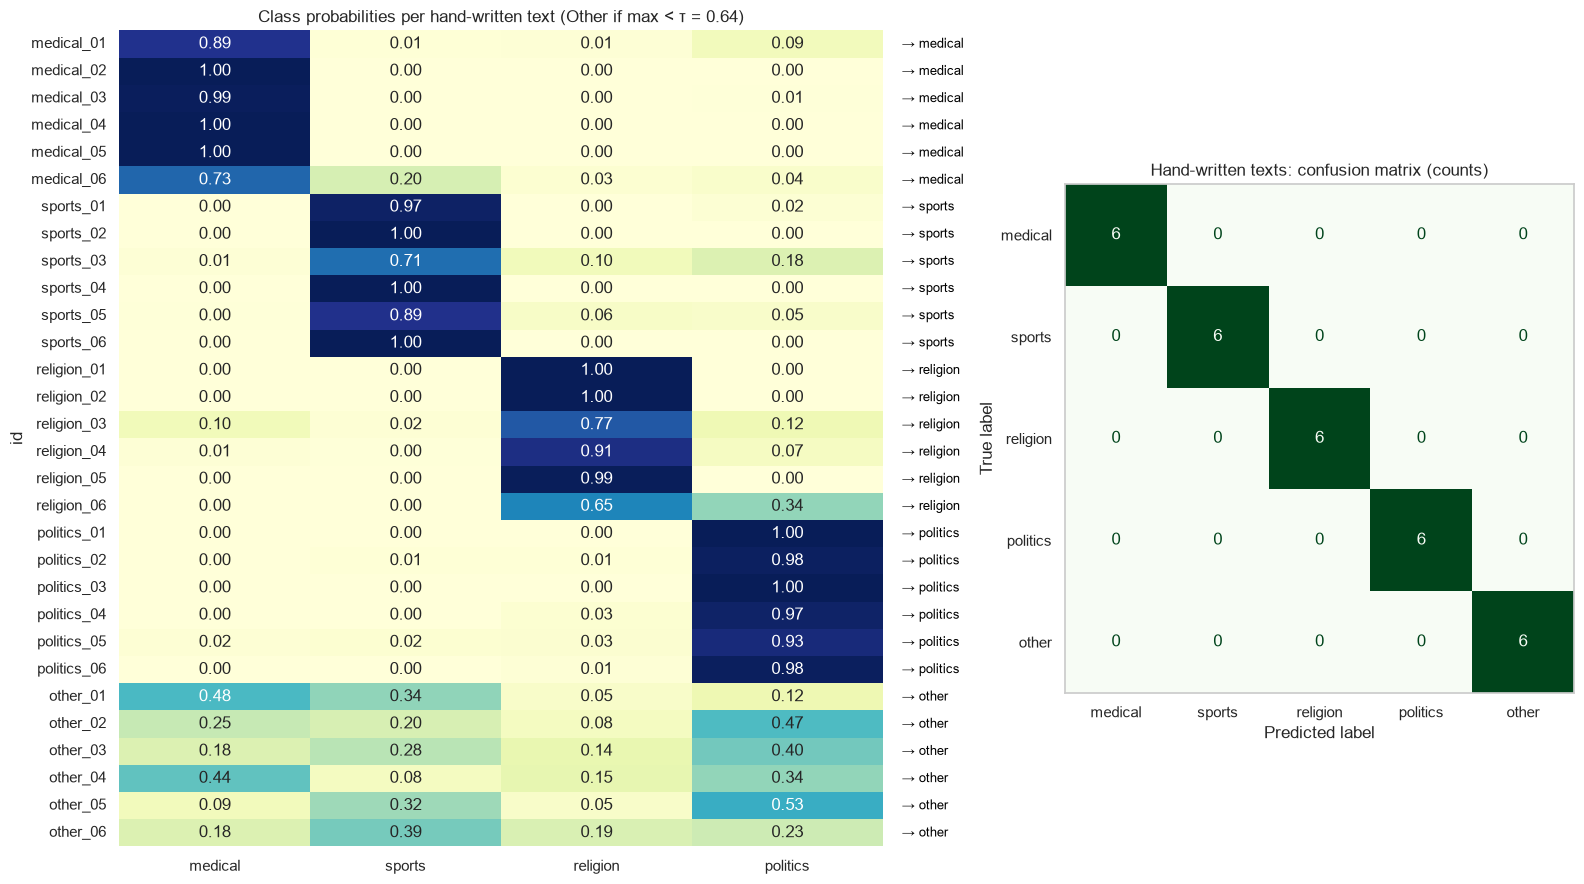

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 9), gridspec_kw={'width_ratios': [3, 2]})
probs = pd.DataFrame(P_hand, columns=MODEL_CLASSES, index=hand['id'])[DOMAINS]
sns.heatmap(probs, annot=True, fmt='.2f', cmap='YlGnBu', cbar=False, ax=axes[0], vmin=0, vmax=1)
axes[0].set_title(f'Class probabilities per hand-written text (Other if max < τ = {TAU:.2f})')
for i, (mx, pred) in enumerate(zip(hand['confidence'], hand['predicted'])):
    axes[0].text(len(DOMAINS) + 0.1, i + 0.5, f'→ {pred}', va='center', fontsize=9,
                 color='#c44e52' if pred != hand['label'].iloc[i] else 'black')
ConfusionMatrixDisplay(confusion_matrix(hand['label'], hand['predicted'], labels=CLASSES),
                       display_labels=CLASSES).plot(ax=axes[1], cmap='Greens', colorbar=False)
axes[1].set_title('Hand-written texts: confusion matrix (counts)')
axes[1].grid(False)
plt.tight_layout(); plt.show()

### 10.1 Classify any text
`classify()` is the complete model as one function: it cleans the text, vectorises it, predicts, applies the *Other* threshold, and
explains the result. Change the examples below to test any three sentences.

In [26]:
def classify(text, show=True):
    p = best_model.predict_proba(tfidf([text]))[0]
    probs = dict(zip(MODEL_CLASSES, p))
    top_cls = MODEL_CLASSES[int(p.argmax())]
    label = top_cls if p.max() >= TAU else 'other'
    lda_dom = DOMAINS[int(lda_scores([text])[0].argmax())]
    if show:
        print(f'TEXT      : {text}')
        print(f'PREDICTED : {label.upper()}   (max probability {p.max():.2f}, threshold {TAU:.2f})')
        print('PROBS     : ' + '  '.join(f'{c}={probs[c]:.2f}' for c in DOMAINS))
        print(f'KEY WORDS : {explain(text, top_cls)}   |   LDA topic model says: {lda_dom}\n')
    return label

examples = [
    "The surgeon said the tumour was removed successfully. She will need chemotherapy for three months. Her oncologist is optimistic about the prognosis.",
    "The striker signed a new four-year contract with the club. He scored twenty goals last season. Fans hope he can lead them to the championship.",
    "The parliament voted to impose new sanctions on the regime. The foreign minister condemned the human rights abuses. The opposition demanded a full inquiry.",
    "Pilgrims gathered at the temple to pray and light candles. The priest read verses from the holy scripture. Many believe the ritual brings blessings to their families.",
    "The recipe needs two cups of rice and a pinch of saffron. Simmer the stock slowly for twenty minutes. Garnish with fresh herbs before serving.",
    "The new laptop has sixteen gigabytes of memory and a fast solid state drive. Its battery lasts about ten hours. It is a good choice for students and programmers.",
]
for e in examples:
    classify(e)

TEXT      : The surgeon said the tumour was removed successfully. She will need chemotherapy for three months. Her oncologist is optimistic about the prognosis.
PREDICTED : MEDICAL   (max probability 0.94, threshold 0.64)
PROBS     : medical=0.94  sports=0.04  religion=0.01  politics=0.01
KEY WORDS : chemotherapy, oncologist, surgeon, prognosis, three month   |   LDA topic model says: medical

TEXT      : The striker signed a new four-year contract with the club. He scored twenty goals last season. Fans hope he can lead them to the championship.
PREDICTED : SPORTS   (max probability 1.00, threshold 0.64)
PROBS     : medical=0.00  sports=1.00  religion=0.00  politics=0.00
KEY WORDS : championship, scored, season, last season, fan   |   LDA topic model says: sports

TEXT      : The parliament voted to impose new sanctions on the regime. The foreign minister condemned the human rights abuses. The opposition demanded a full inquiry.
PREDICTED : POLITICS   (max probability 0.92, threshold 0

## 11. Discussion and Conclusion

In [27]:
summary_tbl = pd.DataFrame({
    'Evaluation set': ['Validation chunks (closed-set, 4 domains)',
                       'Test chunks (closed-set, 4 domains)',
                       'Test + unseen Other chunks (open-set, 5 classes)',
                       'Hand-written outside texts (5 classes)'],
    'Accuracy': [comparison.loc[BEST_NAME, 'accuracy'], accuracy_score(y_test, closed_pred),
                 accuracy_score(y_final, final_pred), (hand.label == hand.predicted).mean()],
    'Macro-F1': [comparison.loc[BEST_NAME, 'macro-F1'], f1_score(y_test, closed_pred, average='macro'),
                 f1_score(y_final, final_pred, labels=CLASSES, average='macro'),
                 f1_score(hand.label, hand.predicted, labels=CLASSES, average='macro')]})
print(f'Final model: TF-IDF (1-2 grams) + {BEST_NAME}, Other threshold τ = {TAU:.2f}; LDA with K = {BEST_K} topics')
display(summary_tbl.style.format({'Accuracy': '{:.3f}', 'Macro-F1': '{:.3f}'}).hide(axis='index'))

Final model: TF-IDF (1-2 grams) + Multinomial Naive Bayes, Other threshold τ = 0.64; LDA with K = 16 topics


Evaluation set,Accuracy,Macro-F1
"Validation chunks (closed-set, 4 domains)",0.892,0.889
"Test chunks (closed-set, 4 domains)",0.894,0.894
"Test + unseen Other chunks (open-set, 5 classes)",0.778,0.793
Hand-written outside texts (5 classes),1.000,1.000


### 11.1 Findings
**Topic modeling reveals the structure of the corpora.** Coherence selected $K = 16$ LDA topics. These are finer than the four domains
and correspond to recognisable sub-themes: baseball pitching, hockey games, medical treatment, health studies, the Israeli–Palestinian
conflict, the Armenian–Azerbaijani conflict, gun law and the Waco siege, Christian doctrine, and philosophical debate about belief. Every
topic maps clearly to one domain (heat-map in §6.2), and topics of the same domain sit close together in the pyLDAvis map. This confirms
that the four domains are separable from word usage alone. NMF produced sharper, more specific topics (e.g. *fbi, batf, koresh, waco*, or
*msg, food, sensitivity*) and classified 3-sentence chunks better than LDA (validation macro-F1 0.80 vs 0.72). This is expected: LDA's
per-document topic estimates are noisy when a text has only ~15 content words.

**Supervised learning is clearly better for the decision itself.** All three TF-IDF classifiers reached ≈ 0.87–0.89 validation macro-F1,
about 9–17 points above the topic-based classifiers. Compressing a text into 16 topic proportions (the hybrid LDA → LogReg model, 0.76)
loses discriminative detail that 66,918 TF-IDF uni/bi-gram features keep. Multinomial Naive Bayes with a uniform class prior was selected.
Naive Bayes is known to perform well on short texts, because its smoothed per-word likelihoods remain reliable when only a few words are present.

**Results on unseen data.**
* Held-out 3-sentence chunks, four domains: **accuracy 0.894, macro-F1 0.894**, almost identical to validation (0.889), so the model did not over-fit the selection process.
* With the *Other* class (τ = 0.64), tested on four newsgroups never used for training or tuning: **macro-F1 0.793**. Between 73% (sci.space) and 87% (misc.forsale) of chunks from these unseen subjects were correctly rejected as *Other*.
* Hand-written modern texts: **30 / 30 correct**, including the ambiguous cases (sports injury → Medical, church funding debate → Religion).

### 11.2 Error analysis and limitations
* **Domain overlap.** `sci.space` texts are the most often mislabelled *Other* (20% go to Politics), because many space posts discuss NASA budgets
  and government policy. Real topics overlap, and a single-label model must choose one.
* **Open-set errors from shared vocabulary.** In the `classify()` demo, the cooking recipe is labelled Medical with probability 0.65, just above τ.
  The sci.med newsgroup contains a long thread about food and MSG sensitivity, so cooking words carry medical weight. A confidence threshold cannot detect
  an off-topic text that happens to use in-domain vocabulary.
* **The *Other* precision is the weakest score (0.54).** Many 3-sentence chunks from real posts are generic ("Thanks for the reply, I agree with you …") and contain
  no topical words, so they are rejected as *Other* even though they come from a domain post. Part of this "error" reflects genuinely uninformative inputs.
* **Bag-of-words ignores word order and meaning.** Synonyms and unseen words (new drug names, current players) are invisible, and the vocabulary is
  from 1993 Usenet.
* **The hand-written test set is small (30 texts) and was written by the author**, so its perfect score should be read as a sanity check rather than a precise accuracy estimate.

### 11.3 Conclusion and future work
The hybrid strategy meets the brief. Unsupervised topic modeling (LDA, NMF) discovers and explains the latent themes of the corpora.
A supervised TF-IDF Naive Bayes classifier with a tuned confidence threshold classifies any three sentences into Medical, Sports, Religion,
Politics or *Other*, with 0.89 macro-F1 on the four domains and 0.79 macro-F1 when unseen off-topic subjects are included.
Possible improvements are:
1. contextual sentence embeddings (e.g. Sentence-BERT) or a fine-tuned transformer, to capture meaning beyond keywords;
2. stronger out-of-distribution scores (distance to class centroids, energy scores), or collecting a broad and diverse *Other* corpus for a dedicated reject class;
3. more modern training text to cover current vocabulary;
4. multi-label output for texts that genuinely span two domains (e.g. sport and medicine).